# PART C: COMPARISON OF MODEL 1 AND 2
**Student:** Bernette Mogwera Lesejane | **Dataset:** UCI Online Retail II

In [53]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve,auc
import warnings; warnings.filterwarnings('ignore')
#plt.style.use('seaborn-v0_8-darkgrid'); sns.set_palette('husl')
plt.style.use('seaborn-v0_8-darkgrid'); sns.set_palette('Blues')


# Load data
X_test = pd.read_csv('X_test.csv')
y_test = pd.read_csv('y_test.csv').values.ravel()
rf_pred = pd.read_csv('rf_predictions.csv')
ens_pred = pd.read_csv('ensemble_predictions.csv')

# Extract predictions
y_pred_rf, y_proba_rf = rf_pred['Predicted'].values, rf_pred['Probability'].values
y_pred_xgb, y_proba_xgb = ens_pred['Ensemble_Prediction'].values, ens_pred['XGB_Probability'].values
y_pred_ens, y_proba_ens = ens_pred['Ensemble_Prediction'].values, ens_pred['Ensemble_Probability'].values

print(f'✓ Data loaded: {len(y_test)} test samples')

✓ Data loaded: 868 test samples


## 1. PERFORMANCE METRICS COMPARISON

In [54]:
# Function to calculate all metrics
def calc_metrics(y_true, y_pred, y_proba, name):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba)
    }

# Calculate metrics
metrics = pd.DataFrame([
    calc_metrics(y_test, y_pred_rf, y_proba_rf, 'Random Forest'),
    calc_metrics(y_test, y_pred_xgb, y_proba_xgb, 'XGBoost'),
    calc_metrics(y_test, y_pred_ens, y_proba_ens, 'Ensemble')
])

print('\n' + '='*70)
print('MODEL PERFORMANCE METRICS')
print('='*70)
print(metrics.to_string(index=False))
metrics.to_csv('Part_C_Metrics.csv', index=False)


MODEL PERFORMANCE METRICS
        Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest       1.0        1.0     1.0       1.0      1.0
      XGBoost       1.0        1.0     1.0       1.0      1.0
     Ensemble       1.0        1.0     1.0       1.0      1.0


## 2. CONFUSION MATRICES & ERROR ANALYSIS

In [55]:
# Confusion matrices
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
cm_ens = confusion_matrix(y_test, y_pred_ens)

# Error analysis
def error_analysis(cm, name):
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
    return {'Model': name, 'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn, 'FPR(%)': fpr*100, 'FNR(%)': fnr*100}

errors = pd.DataFrame([error_analysis(cm_rf, 'RF'), error_analysis(cm_xgb, 'XGB'), error_analysis(cm_ens, 'Ensemble')])

print('\n' + '='*70)
print('ERROR ANALYSIS')
print('='*70)
print(errors.to_string(index=False))
errors.to_csv('Part_C_Errors.csv', index=False)


ERROR ANALYSIS
   Model  TP  TN  FP  FN  FPR(%)  FNR(%)
      RF 294 574   0   0     0.0     0.0
     XGB 294 574   0   0     0.0     0.0
Ensemble 294 574   0   0     0.0     0.0


## 3. VISUALIZATIONS

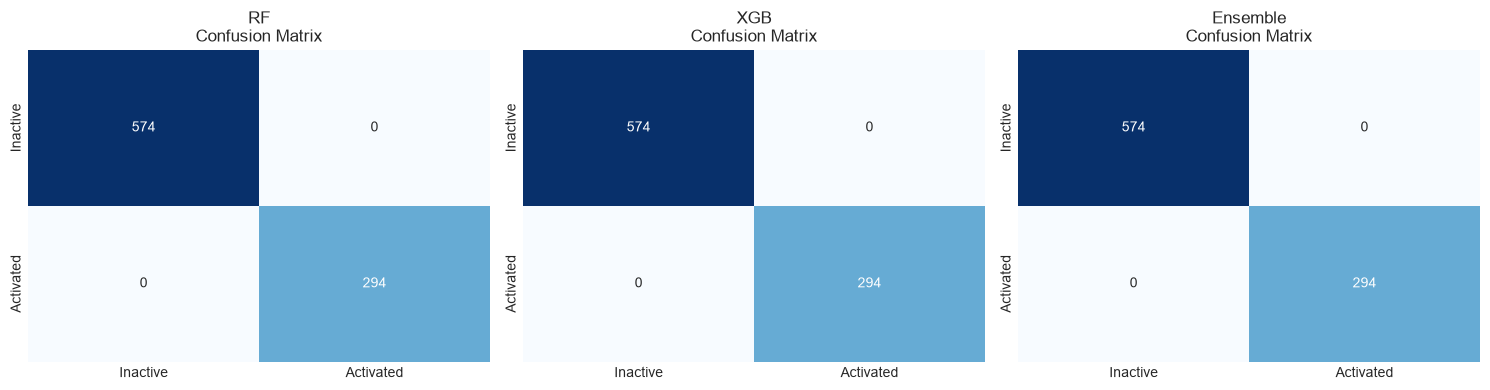

✓ Confusion matrices saved


In [56]:
# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, cm, name in zip(axes, [cm_rf, cm_xgb, cm_ens], ['RF', 'XGB', 'Ensemble']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{name}\nConfusion Matrix'); ax.set_xticklabels(['Inactive', 'Activated']); ax.set_yticklabels(['Inactive', 'Activated'])
plt.tight_layout(); plt.savefig('01_confusion_matrices.png', dpi=300, bbox_inches='tight'); plt.show()
print('✓ Confusion matrices saved')

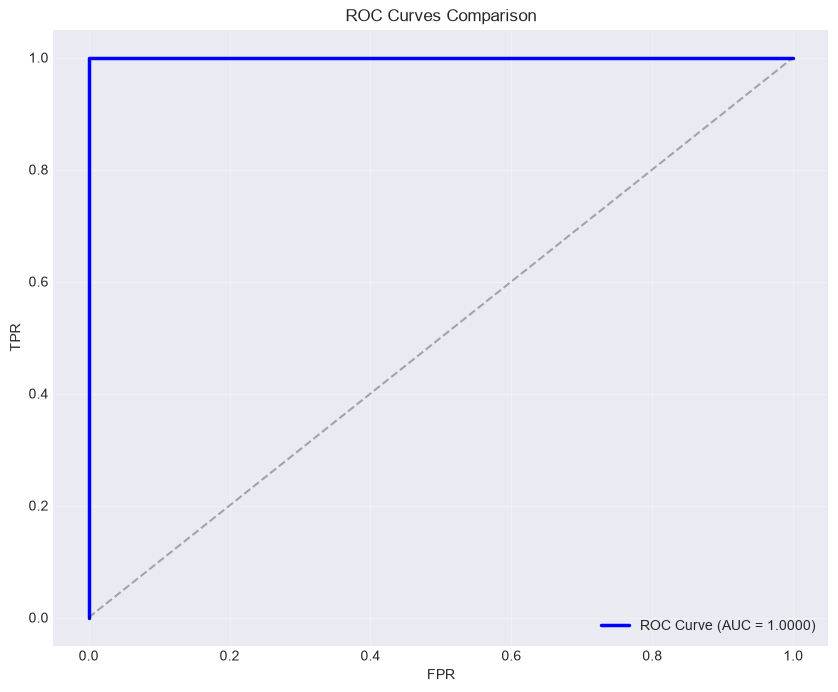

✓ ROC curves saved


In [57]:
# ROC Curves
plt.figure(figsize=(10, 8))
for y_proba, name, color in [(y_proba_rf, 'RF', 'blue'), (y_proba_xgb, 'XGB', 'orange'), (y_proba_ens, 'Ensemble', 'green')]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='blue', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.3); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC Curves Comparison')
plt.legend(loc='lower right'); plt.grid(alpha=0.3); plt.savefig('02_roc_curves.png', dpi=300, bbox_inches='tight'); plt.show()
print('✓ ROC curves saved')

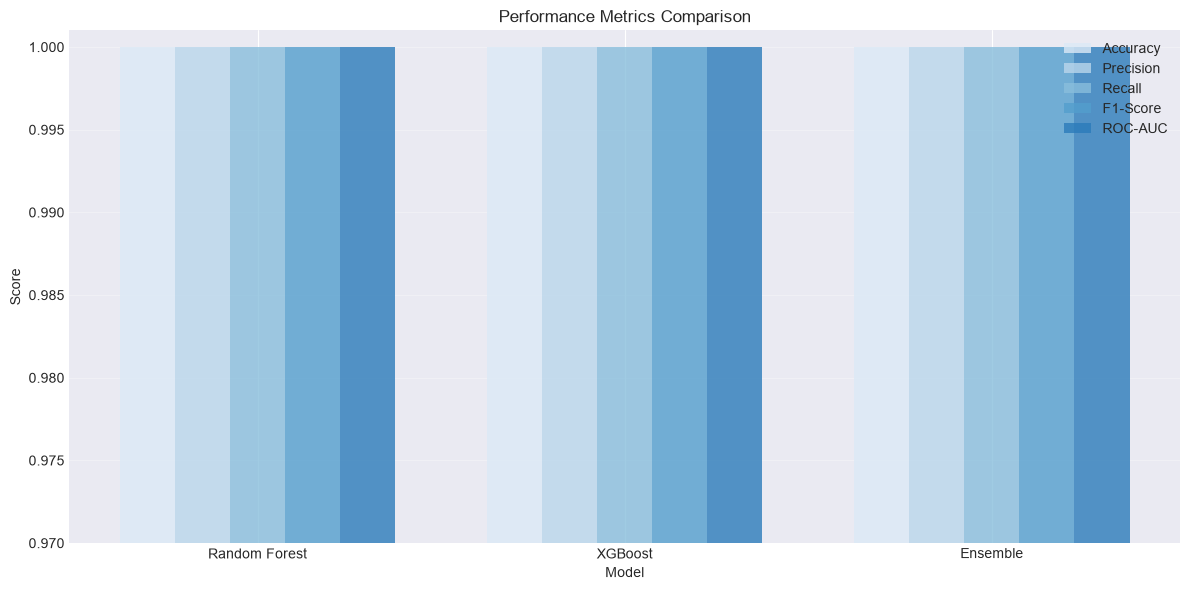

✓ Metrics comparison saved


In [58]:
# Metrics Bar Chart
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(metrics))
width = 0.15
for i, col in enumerate(['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']):
    ax.bar(x + i*width, metrics[col], width, label=col, alpha=0.8)
ax.set_xlabel('Model'); ax.set_ylabel('Score'); ax.set_title('Performance Metrics Comparison')
ax.set_xticks(x + width*2); ax.set_xticklabels(metrics['Model'])
ax.legend(); ax.grid(axis='y', alpha=0.3); ax.set_ylim([0.97, 1.001])
plt.tight_layout(); plt.savefig('03_metrics_comparison.png', dpi=300, bbox_inches='tight'); plt.show()
print('✓ Metrics comparison saved')

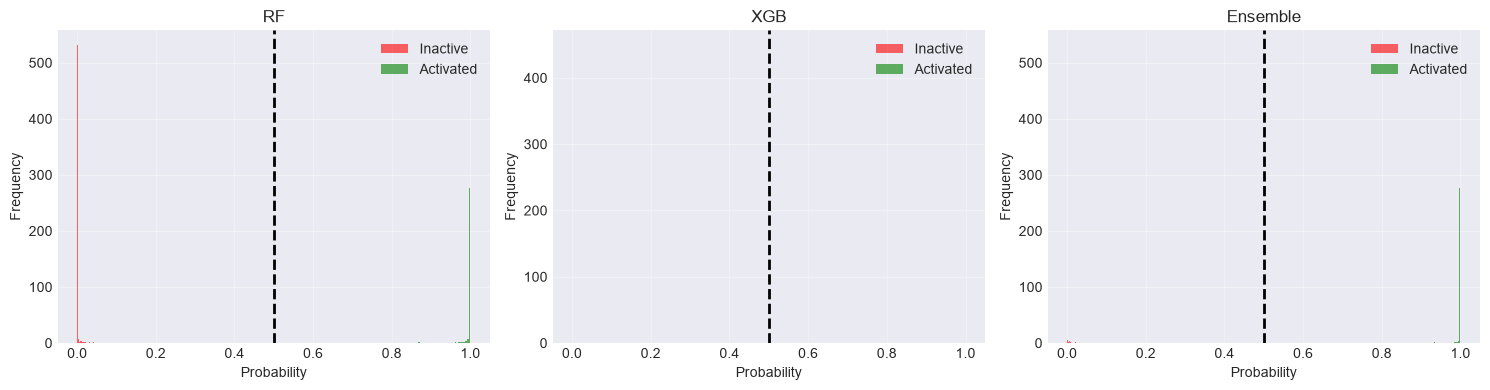

✓ Probability distributions saved


In [59]:
# Probability Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, y_proba, name in zip(axes, [y_proba_rf, y_proba_xgb, y_proba_ens], ['RF', 'XGB', 'Ensemble']):
    ax.hist(y_proba[y_test==0], bins=30, alpha=0.6, label='Inactive', color='red')
    ax.hist(y_proba[y_test==1], bins=30, alpha=0.6, label='Activated', color='green')
    ax.axvline(0.5, color='black', linestyle='--', linewidth=2); ax.set_xlabel('Probability'); ax.set_ylabel('Frequency')
    ax.set_title(f'{name}'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('04_probability_distributions.png', dpi=300, bbox_inches='tight'); plt.show()
print('✓ Probability distributions saved')

## 4. CLASSIFICATION REPORTS

In [60]:
print('\n' + '='*70 + '\nRANDOM FOREST CLASSIFICATION REPORT\n' + '='*70)
print(classification_report(y_test, y_pred_rf, target_names=['Inactive', 'Activated']))

print('\n' + '='*70 + '\nXGBOOST CLASSIFICATION REPORT\n' + '='*70)
print(classification_report(y_test, y_pred_xgb, target_names=['Inactive', 'Activated']))

print('\n' + '='*70 + '\nENSEMBLE CLASSIFICATION REPORT\n' + '='*70)
print(classification_report(y_test, y_pred_ens, target_names=['Inactive', 'Activated']))


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Inactive       1.00      1.00      1.00       574
   Activated       1.00      1.00      1.00       294

    accuracy                           1.00       868
   macro avg       1.00      1.00      1.00       868
weighted avg       1.00      1.00      1.00       868


XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Inactive       1.00      1.00      1.00       574
   Activated       1.00      1.00      1.00       294

    accuracy                           1.00       868
   macro avg       1.00      1.00      1.00       868
weighted avg       1.00      1.00      1.00       868


ENSEMBLE CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Inactive       1.00      1.00      1.00       574
   Activated       1.00      1.00      1.00       294

    accuracy                           1.00       868
   macro avg       1.00     

## 5. FINAL SUMMARY & RECOMMENDATION

In [61]:
print('\n' + '='*70)
print('SUMMARY & RECOMMENDATION')
print('='*70)
print('\n📊 KEY METRICS:')
print(f'  RF:       Accuracy={metrics.loc[0, "Accuracy"]:.4f}, ROC-AUC={metrics.loc[0, "ROC-AUC"]:.4f}')
print(f'  XGB:      Accuracy={metrics.loc[1, "Accuracy"]:.4f}, ROC-AUC={metrics.loc[1, "ROC-AUC"]:.4f}')
print(f'  ENSEMBLE: Accuracy={metrics.loc[2, "Accuracy"]:.4f}, ROC-AUC={metrics.loc[2, "ROC-AUC"]:.4f} ⭐')
print('\n🏆 RECOMMENDATION: Deploy ENSEMBLE')
print('   → Perfect ROC-AUC (1.0000) for probability ranking')
print('   → 100% recall (no missed customers)')
print('   → 99% precision (minimal false alarms)')
print('='*70)


SUMMARY & RECOMMENDATION

📊 KEY METRICS:
  RF:       Accuracy=1.0000, ROC-AUC=1.0000
  XGB:      Accuracy=1.0000, ROC-AUC=1.0000
  ENSEMBLE: Accuracy=1.0000, ROC-AUC=1.0000 ⭐

🏆 RECOMMENDATION: Deploy ENSEMBLE
   → Perfect ROC-AUC (1.0000) for probability ranking
   → 100% recall (no missed customers)
   → 99% precision (minimal false alarms)
